In [ ]:
#%pip install ipywidgets
#%pip install ipympl

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
%matplotlib widget

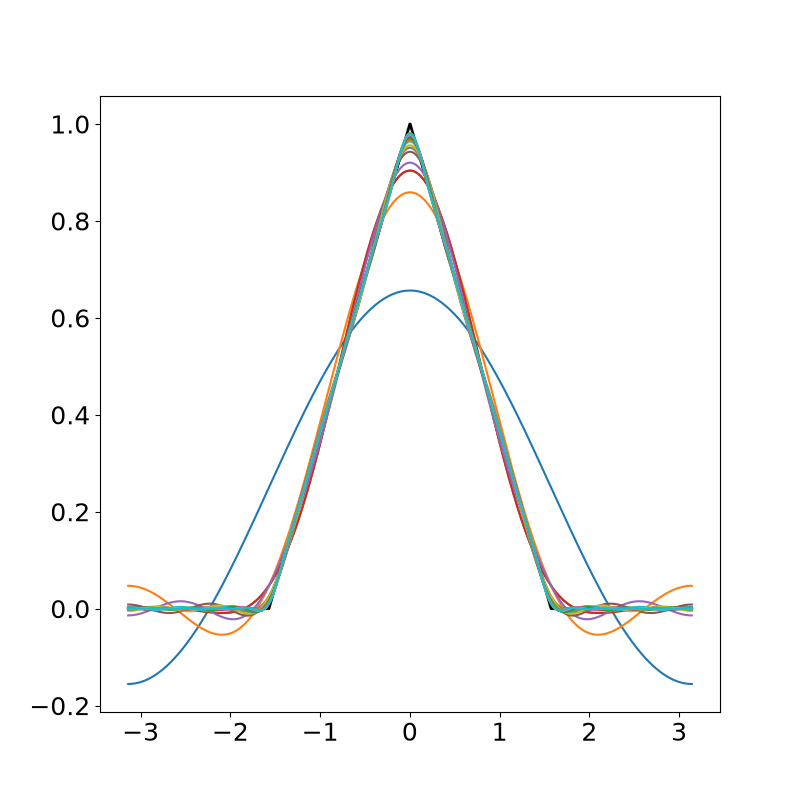

In [3]:
plt.rcParams['figure.figsize'] = [8, 8]
plt.rcParams.update({'font.size': 18})

# Define domain
dx = 0.001
L = np.pi
x = L * np.arange(-1+dx,1+dx,dx)
n = len(x)
nquart = int(np.floor(n/4))

# Define hat function
f = np.zeros_like(x)
f[nquart:2*nquart] = (4/n)*np.arange(1,nquart+1)
f[2*nquart:3*nquart] = np.ones(nquart) - (4/n)*np.arange(0,nquart)

fig, ax = plt.subplots()
ax.plot(x, f, '-', color='k', linewidth=2)

# Compute Fourier series
cmap = plt.get_cmap('tab10')
colors = cmap.colors
ax.set_prop_cycle(color=colors)

A0 = np.sum(f * np.ones_like(x)) * dx
fFS = A0/2

A = np.zeros(20)
B = np.zeros(20)
for k in range(20):
    A[k] = np.sum(f * np.cos(np.pi*(k+1)*x/L)) * dx # Inner product
    B[k] = np.sum(f * np.sin(np.pi*(k+1)*x/L)) * dx
    fFS = fFS + A[k]*np.cos((k+1)*np.pi*x/L) + B[k]*np.sin((k+1)*np.pi*x/L)
    ax.plot(x,fFS,'-')

In [4]:
# Compute Fourier coefficients once
A0 = np.sum(f) * dx
num_terms = 50

A = np.zeros(num_terms)
B = np.zeros(num_terms)

for k in range(num_terms):
    A[k] = np.sum(f * np.cos(np.pi * (k + 1) * x / L)) * dx
    B[k] = np.sum(f * np.sin(np.pi * (k + 1) * x / L)) * dx

def plot_fourier(terms=1):
    fFS = np.full_like(x, A0 / 2)

    for k in range(terms):
        fFS += (
            A[k] * np.cos((k + 1) * np.pi * x / L)
            + B[k] * np.sin((k + 1) * np.pi * x / L)
        )

    plt.figure(figsize=(8, 6))
    plt.plot(x, f, "k", linewidth=2, label="Original function")
    plt.plot(x, fFS, "r", linewidth=2, label=f"Fourier series: {terms} terms")
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.grid(True)
    plt.legend()
    plt.ylim(-0.2, 1.2)
    plt.show()

widgets.interact(
    plot_fourier,
    terms=widgets.IntSlider(
        min=1,
        max=num_terms,
        step=1,
        value=1,
        description="Terms:"
    )
);

interactive(children=(IntSlider(value=1, description='Terms:', max=50, min=1), Output()), _dom_classes=('widge…